### Visualización de datos 

El objetivo de este apartado es facilitar la interpretación de los datos y elaborar un gráfico de barras, permitiendo comparar de forma visual la demanda media de bicicletas en La Seu y Beniferri para cada una de las 24 horas del día, ayudando a identificar diferencias en los patrones de uso entre ambos barrios. 

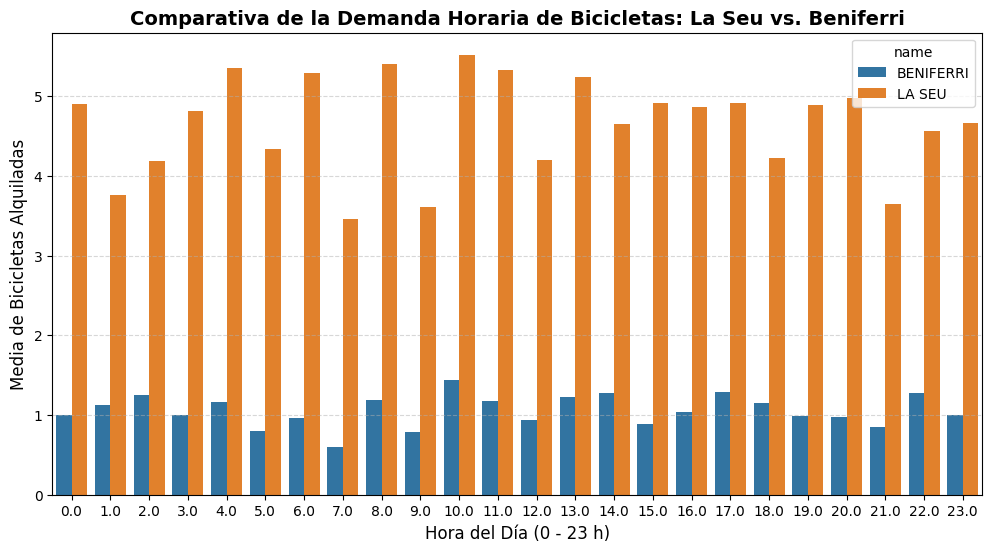

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga del archivo usando la ruta absoluta completa de tu Mac
df = pd.read_csv("/Users/mac/documents/proyecto/data/interim/usobarriosmeteo.csv", sep=";")

# 2. Corrección horaria (ciclo diario de 0 a 23 horas)
df['hr'] = df['hr'] % 24

# 3. Filtrar para los dos barrios asignados
df_filtrado = df[(df['name'] == 'LA SEU') | (df['name'] == 'BENIFERRI')]

# 4. Agrupación matemática directa (Estándar de 2º curso)
# Calculamos la media de uso agrupando por hora y por barrio, y reseteamos el índice
df_agrupado = df_filtrado.groupby(['hr', 'name'])['uso_bici'].mean().reset_index()

# 5. Configurar el lienzo del gráfico
plt.figure(figsize=(12, 6))

# 6. Creación del gráfico de barras emparejadas (barplot)
sns.barplot(
    data=df_agrupado, 
    x='hr', 
    y='uso_bici', 
    hue='name'
)

# 7. Personalización académica del gráfico
plt.title('Comparativa de la Demanda Horaria de Bicicletas: La Seu vs. Beniferri', fontsize=14, fontweight='bold')
plt.xlabel('Hora del Día (0 - 23 h)', fontsize=12)
plt.ylabel('Media de Bicicletas Alquiladas', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 8. Guardar y mostrar
plt.savefig('/Users/mac/documents/proyecto/data/interim/grafico_barplot.png', dpi=300)
plt.show()